# Incremental search on actual mesh vertices

All timings are from one fresh frozen study. Ratios above one favor the candidate; incomplete navigation is never a time win. Intermediate mesh vertices carry g, learned h, OPEN entries and policies.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
ad=root/'cpp/mesh_vertex/results/full/analysis'
a=json.loads((ad/'analysis.json').read_text())
assert a['status']=='passed'
for name,h in a['tables_sha256'].items():
    assert hashlib.sha256((ad/name).read_bytes()).hexdigest()==h
{k:a[k] for k in ['scenarios','timed_runs','memory_runs','allocation_matched_rows','exact_cost_disagreements','capped_calls','contour_equivalence_queries','count_only_runs']}

{'scenarios': 232,
 'timed_runs': 8964,
 'memory_runs': 2988,
 'allocation_matched_rows': 57001,
 'exact_cost_disagreements': 0,
 'capped_calls': 393,
 'contour_equivalence_queries': 2678,
 'count_only_runs': 2316}

,cohort,control,panel,method,baseline,configurations,pairs,full_speedup,repair_speedup,memory_multiplier,wins10
1,navigation_dynamic,car16,navigation,cascade_mesh,best_control,36,17,0.546010,0.661732,3.998107,3
6,navigation_dynamic,car16,navigation,cascade_mesh,mesh_mpgaa,36,17,1.536466,4.052468,1.000845,9
7,navigation_dynamic,car16,navigation,cascade_mesh,trigger_mesh,36,17,1.073891,1.110202,1.000000,5
9,navigation_dynamic,car16,navigation,trigger_mesh,best_control,36,17,0.508441,0.596046,3.998107,2
15,navigation_dynamic,car16,navigation,trigger_mesh,mesh_mpgaa,36,17,1.430746,3.650207,1.000845,9
17,navigation_unknown,car16,navigation,cascade_mesh,best_control,48,45,0.519952,0.533020,3.275614,0
22,navigation_unknown,car16,navigation,cascade_mesh,mesh_mpgaa,48,45,0.844723,0.891771,1.000998,3
23,navigation_unknown,car16,navigation,cascade_mesh,trigger_mesh,48,45,1.063739,1.044788,1.000000,14
25,navigation_unknown,car16,navigation,trigger_mesh,best_control,48,45,0.488797,0.510170,3.275614,0
31,navigation_unknown,car16,navigation,trigger_mesh,mesh_mpgaa,48,45,0.794108,0.853542,1.000998,1


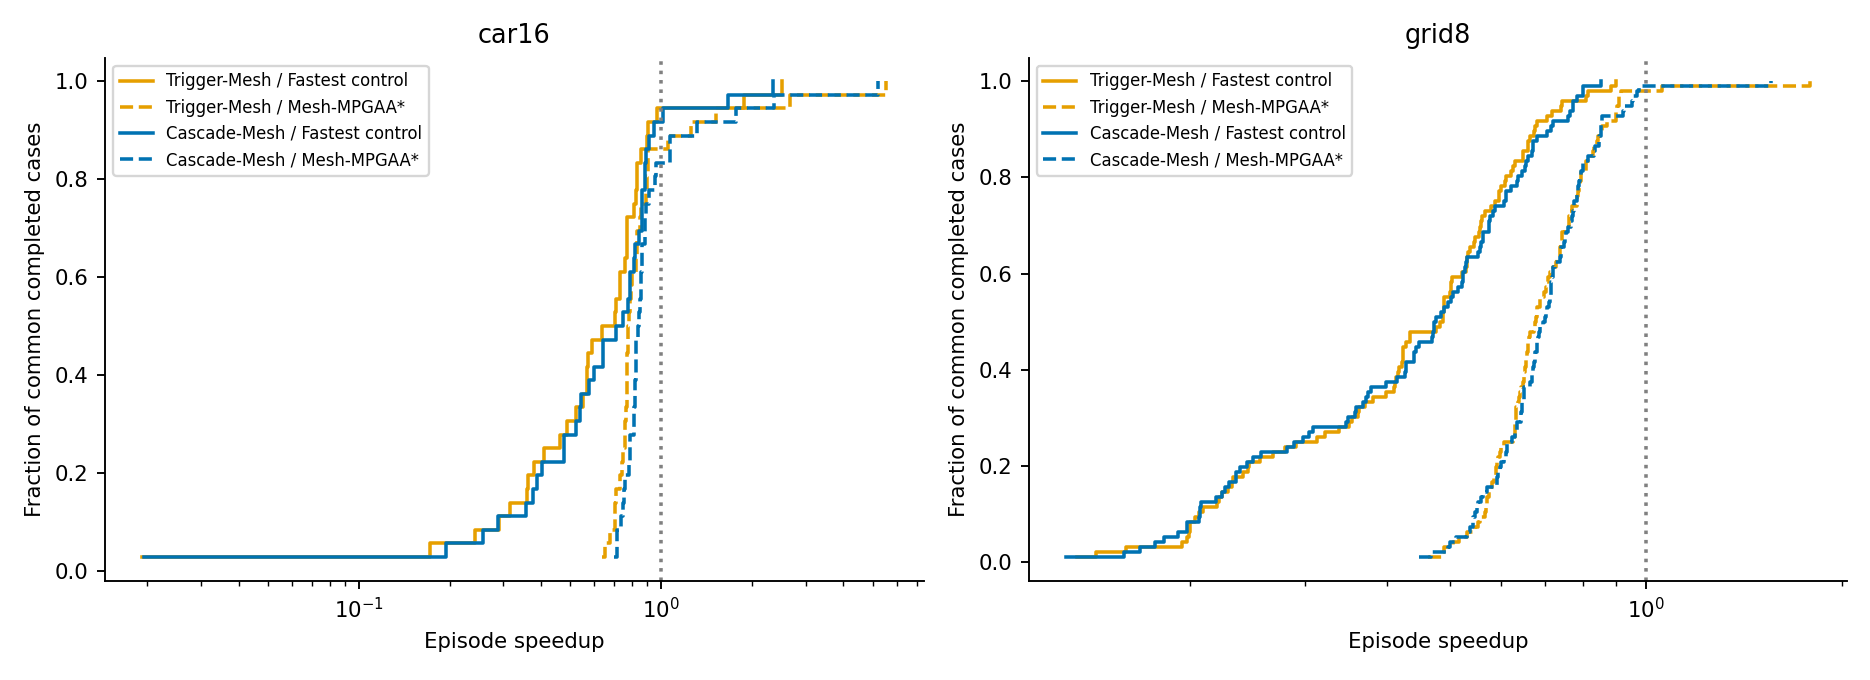

In [2]:
s=pd.read_csv(ad/'summary.csv')
display(s[s.baseline.isin(['best_control','mesh_mpgaa','trigger_mesh','contour_only','cascade_heap'])])
display(Image(filename=str(root/'docs/mesh_vertex/figures/profile.png')))

,cohort,control,map,method,baseline,configurations,pairs,full_speedup,repair_speedup,memory_multiplier,wins10
1,navigation_dynamic,car16,AR0700,cascade_mesh,best_control,6,2,0.649084,1.649114,4.157962,1
9,navigation_dynamic,car16,AR0700,trigger_mesh,best_control,6,2,0.594358,1.535036,4.157962,1
17,navigation_dynamic,car16,Berlin,cascade_mesh,best_control,6,2,0.400724,0.398697,4.901304,0
25,navigation_dynamic,car16,Berlin,trigger_mesh,best_control,6,2,0.366154,0.320520,4.901304,0
33,navigation_dynamic,car16,MA_maze96,cascade_mesh,best_control,6,0,NaN,NaN,NaN,0
41,navigation_dynamic,car16,MA_maze96,trigger_mesh,best_control,6,0,NaN,NaN,NaN,0
49,navigation_dynamic,car16,MA_random96,cascade_mesh,best_control,6,5,0.777814,1.188078,3.883549,1
57,navigation_dynamic,car16,MA_random96,trigger_mesh,best_control,6,5,0.723775,1.080823,3.883549,0
65,navigation_dynamic,car16,MA_room96,cascade_mesh,best_control,6,4,0.186429,0.109122,10.014723,0
73,navigation_dynamic,car16,MA_room96,trigger_mesh,best_control,6,4,0.179079,0.095546,10.014723,0


,cohort,control,map,radius,k,cr,method,baseline,configurations,pairs,full_speedup,repair_speedup,memory_multiplier,wins10
6,navigation_dynamic,car16,AR0700,0,2,5,cascade_mesh,mesh_mpgaa,2,0,NaN,NaN,NaN,0
15,navigation_dynamic,car16,AR0700,0,2,5,trigger_mesh,mesh_mpgaa,2,0,NaN,NaN,NaN,0
22,navigation_dynamic,car16,AR0700,0,8,10,cascade_mesh,mesh_mpgaa,2,1,7.386300,10.967062,1.006823,1
31,navigation_dynamic,car16,AR0700,0,8,10,trigger_mesh,mesh_mpgaa,2,1,6.812905,10.208413,1.006823,1
38,navigation_dynamic,car16,AR0700,0,32,20,cascade_mesh,mesh_mpgaa,2,1,0.893375,NaN,1.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
639,navigation_unknown,car16,arena,16,0,0,trigger_mesh,mesh_mpgaa,2,2,0.937984,1.064477,1.000000,0
646,navigation_unknown,car16,arena,32,0,0,cascade_mesh,mesh_mpgaa,2,2,1.000220,1.004593,1.000000,0
655,navigation_unknown,car16,arena,32,0,0,trigger_mesh,mesh_mpgaa,2,2,1.007153,1.006960,1.000000,0
662,navigation_unknown,car16,arena,64,0,0,cascade_mesh,mesh_mpgaa,2,2,0.903423,NaN,1.000000,0


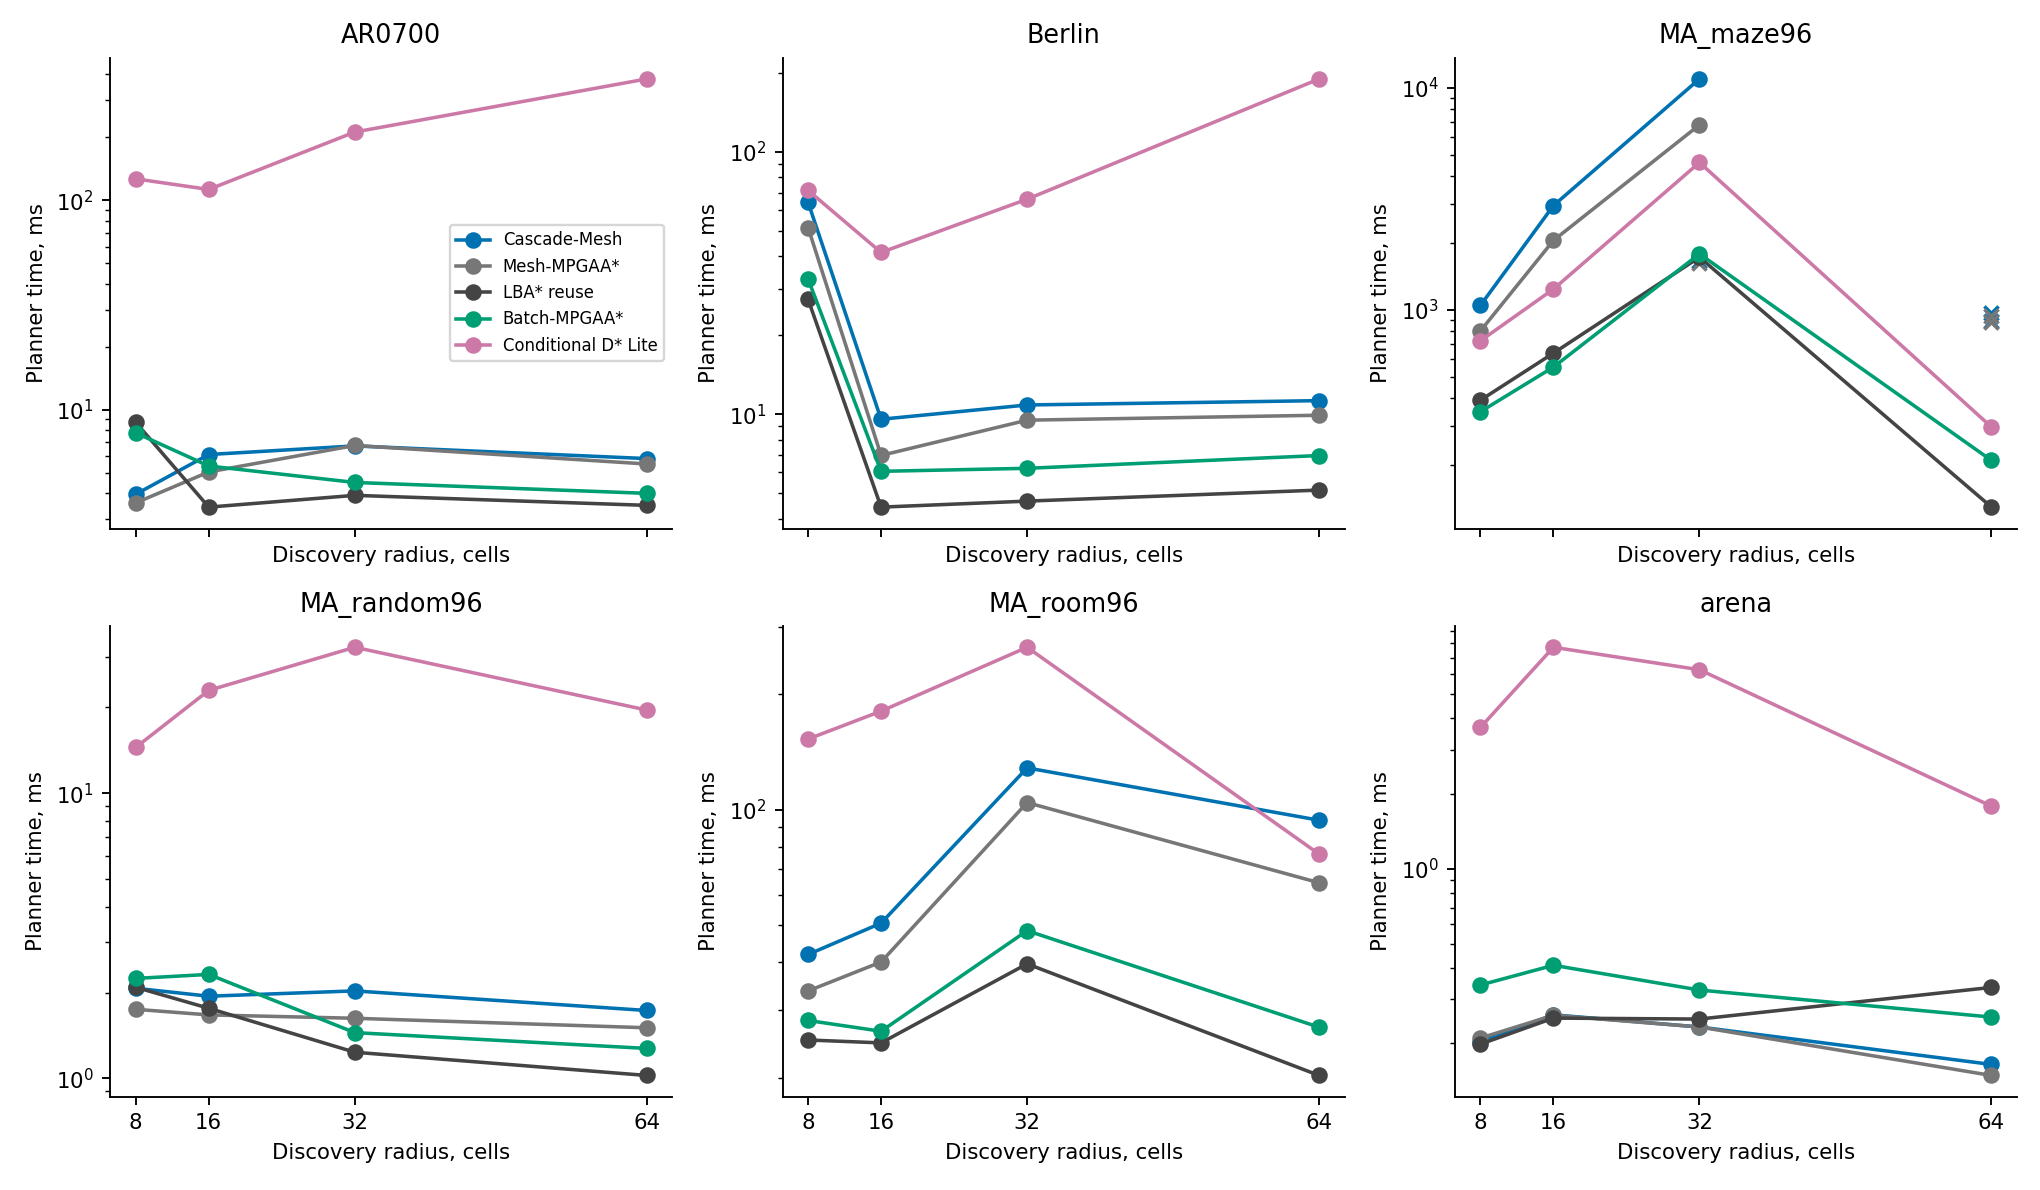

In [3]:
m=pd.read_csv(ad/'map_pairs.csv')
display(m[m.baseline.eq('best_control')])
display(pd.read_csv(ad/'parameter_pairs.csv').query("baseline=='mesh_mpgaa' and cohort!='replay'"))
display(Image(filename=str(root/'docs/mesh_vertex/figures/radius.png')))

,mv_boundary_expansions,mv_interior_expansions,notify_probes,mv_heap_pushes,mv_repair_heap_pushes,mv_repair_local_steps
method,,,,,,
batch_mpgaa,0,0,96042,0,0,0
boundary_mesh,0,0,1479760,0,0,0
cascade_heap,820655,13634613,449,15199389,1346,1609
cascade_mesh,820655,13634613,449,8443907,1346,1609
cascade_scan,820655,13634613,380800,8443907,1346,1609
cmesh_dstar,0,0,2523248,0,0,0
conditional_dstar,0,0,1423920,0,0,0
contour_only,820655,13634613,449,8443907,2955,0
lba_reuse,0,0,0,0,0,0


,cohort,control,method,configurations,complete
0,navigation_dynamic,car16,batch_mpgaa,36,25
1,navigation_dynamic,car16,cascade_mesh,36,17
2,navigation_dynamic,car16,cmesh_dstar,36,25
3,navigation_dynamic,car16,conditional_dstar,36,25
4,navigation_dynamic,car16,lba_reuse,36,24
5,navigation_dynamic,car16,md_astar,36,25
6,navigation_dynamic,car16,mesh_mpgaa,36,17
7,navigation_dynamic,car16,trigger_mesh,36,17
8,navigation_unknown,car16,batch_mpgaa,48,48
9,navigation_unknown,car16,cascade_mesh,48,45


all_free_calls  online_calls
control method                                         
car16   batch_mpgaa              68388068      55103271
        boundary_mesh            95916163      68858637
        cascade_heap             20022501      10243282
        cascade_mesh             20022501      10243282
        cascade_scan             20022501      10243282
        cmesh_dstar              58606307      23103940
        conditional_dstar        38410540      28617427
        contour_only             20022501      10243282
        lba_reuse               101981020      90606095
        md_astar                 57805696      46430771
        mesh_astar               23108623      13329404
        mesh_mpgaa               20022501      10243282
        mesha                   124068973     111346696
        mpgaa                    57482178      46107357
        trigger_mesh             20022501      10243282
grid8   batch_mpgaa                844980        564084
        boundary_mesh              849436        446116
        cascade_heap               743789        462893
        cascade_mesh               743789        462893
        cascade_scan               743737        462841
        cmesh_dstar               1139263        323899
        conditional_dstar          195474         78942
        contour_only               743789        462893
        lba_reuse                  988002        850554
        md_astar                   227812         90364
        mesh_astar                2213044       1932148
        mesh_mpgaa                 743737        462841
        mesha                     2213044       1932148
        mpgaa                      227363         90107
        octile_reuse               775054        678454
        trigger_mesh               743789        462893

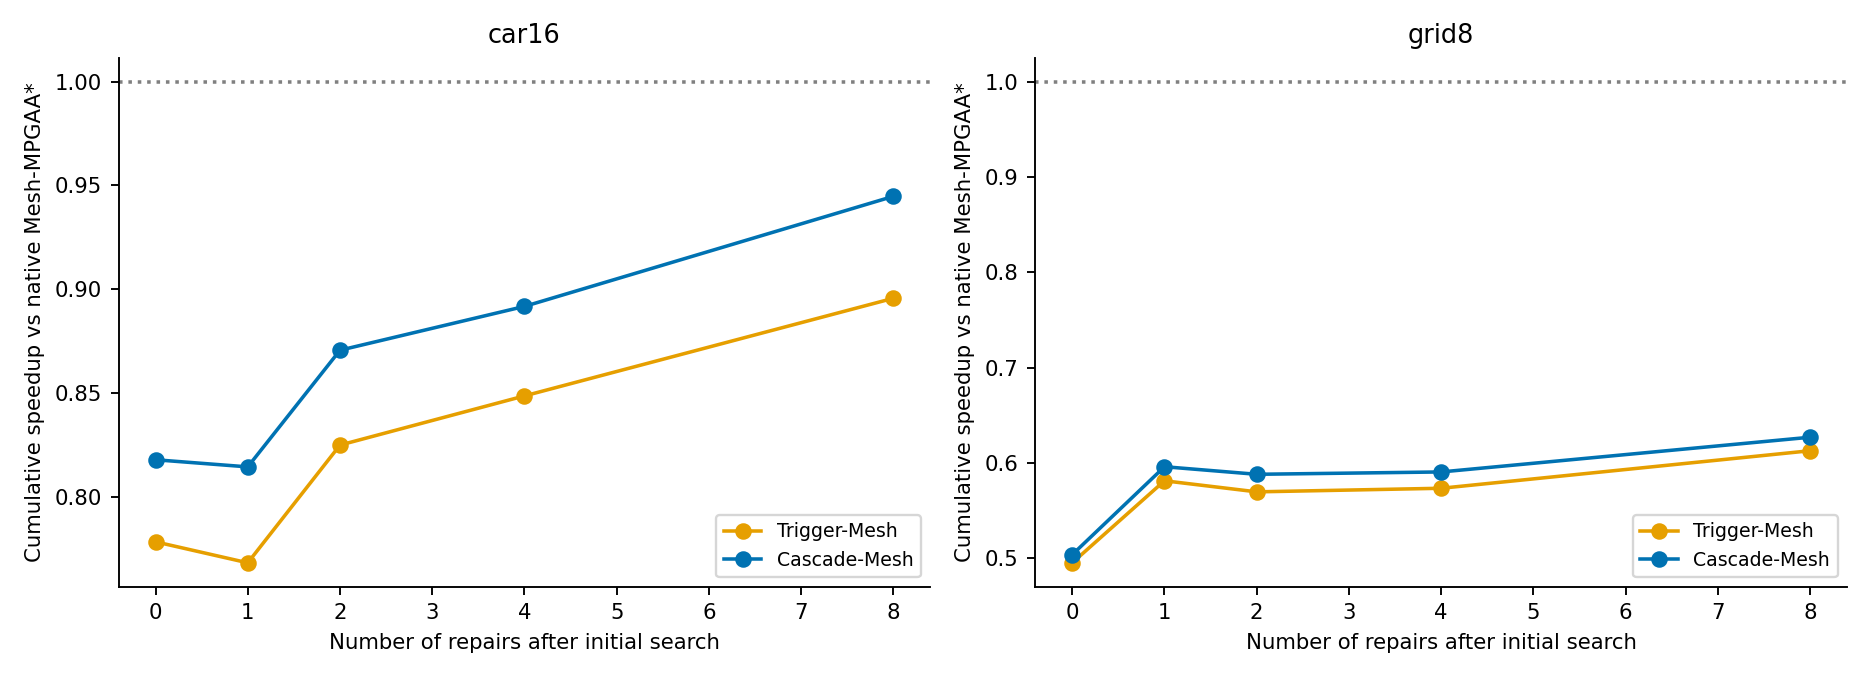

In [4]:
w=pd.read_csv(ad/'work.csv')
display(w.query("cohort=='replay' and control=='car16' and panel=='main'").groupby('method')[['mv_boundary_expansions','mv_interior_expansions','notify_probes','mv_heap_pushes','mv_repair_heap_pushes','mv_repair_local_steps']].sum())
display(pd.read_csv(ad/'completion.csv'))
display(pd.read_csv(ad/'collision_probes.csv').groupby(['control','method'])[['all_free_calls','online_calls']].sum())
display(Image(filename=str(root/'docs/mesh_vertex/figures/amortization.png')))

Snapshot fields are not additive work; old checked_cells has partial coverage, so the independent all-Grid.free pass supplies common API counts. The contribution hypothesis concerns the mesh repair combination; MPGAA*, watched dependencies, potentials and fringe processing have prior work. Per-map losses, caps, clamped rates, trajectories, peak memory and full claim limits are retained in report.pdf and related_work.md.